# 01 – Exploratory Data Analysis

First look at the data, focused on what tasks **(a)** (regular-season ranking) and **(b)** (coach changes) need.

Remember the rule: predictions for season *Y* are made the day before it starts, so only seasons **before Y** can be used as features.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data import load_all

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

tables = load_all()
teams = tables["Teams"]
coaches = tables["Coaches"]

## 1. Overview of all tables

In [2]:
def summarize(name, df):
    years = df["year"] if "year" in df else None
    return {
        "table": name,
        "rows": len(df),
        "cols": df.shape[1],
        "first_year": years.min() if years is not None else None,
        "last_year": years.max() if years is not None else None,
        "% missing cells": round(100 * df.isna().mean().mean(), 1),
    }

pd.DataFrame([summarize(n, df) for n, df in tables.items()]).sort_values("rows", ascending=False)

,table,rows,cols,first_year,last_year,% missing cells
10,Scoring,43848,31,1909.0,2009.0,34.1
16,TeamVsTeam,23862,8,1909.0,2009.0,10.3
9,Master,7469,31,NaN,NaN,38.8
5,Goalies,4096,23,1909.0,2009.0,30.8
2,AwardsPlayers,2021,6,1917.0,2009.0,22.5
3,Coaches,1741,14,1909.0,2009.0,21.0
12,ScoringShootout,1487,7,2005.0,2009.0,0.0
15,TeamSplits,1459,43,1909.0,2009.0,33.2
17,Teams,1459,27,1909.0,2009.0,21.7
19,TeamsPost,895,17,1913.0,2009.0,15.3


## 2. Teams: which seasons and leagues?

The data covers 1909–2009 and several leagues. Only the NHL matters for a modern prediction.

In [3]:
teams.groupby("lgID")["year"].agg(["min", "max", "count"])

,min,max,count
lgID,,,
NHA,1909,1916,45
NHL,1917,2009,1265
PCHA,1911,1923,41
WCHL,1921,1925,24
WHA,1972,1978,84


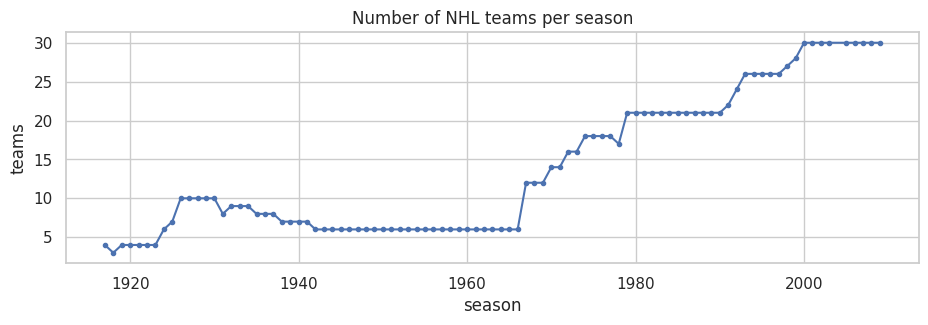

Seasons missing from the data: [2004]


In [4]:
nhl = teams[teams["lgID"] == "NHL"].copy()
per_year = nhl.groupby("year").size()

fig, ax = plt.subplots(figsize=(11, 3))
per_year.plot(ax=ax, marker=".")
ax.set(title="Number of NHL teams per season", xlabel="season", ylabel="teams")
plt.show()

all_years = set(range(nhl["year"].min(), nhl["year"].max() + 1))
print("Seasons missing from the data:", sorted(all_years - set(per_year.index)))

Games per season changed over time (and 1994 was a 48-game lockout season), so raw points (`Pts`) are not comparable across years.
We use **points percentage** = `Pts / (2 * G)` instead.

In [5]:
nhl["pts_pct"] = nhl["Pts"] / (2 * nhl["G"])
nhl.groupby("year")["G"].max().loc[1975:].to_frame("games per team").T

year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2005,2006,2007,2008,2009
games per team,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,84,84,48,82,82,82,82,82,82,82,82,82,82,82,82,82,82


### Which columns exist in which era?

Some statistics were only recorded from a certain year (e.g. overtime losses, shootouts).

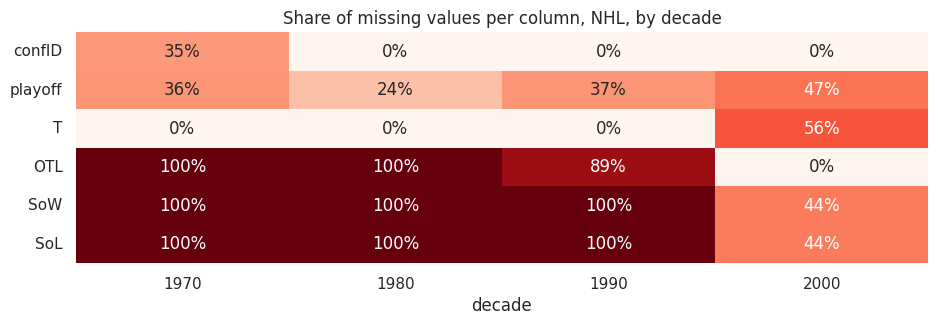

In [6]:
modern = nhl[nhl["year"] >= 1970]
missing_by_decade = modern.groupby(modern["year"] // 10 * 10).agg(lambda s: s.isna().mean())
missing_by_decade = missing_by_decade.loc[:, missing_by_decade.max() > 0].drop(columns=["year"], errors="ignore")

fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(missing_by_decade.T.astype(float), annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=ax)
ax.set(title="Share of missing values per column, NHL, by decade", xlabel="decade", ylabel="")
plt.show()

## 3. What does `rank` mean?

Check whether `rank` is the position **inside the division** (by points) or league-wide.

In [7]:
recent = nhl[nhl["year"] >= 1990].copy()
recent["div_rank_by_pts"] = recent.groupby(["year", "divID"])["Pts"].rank(ascending=False, method="min")
recent["league_rank_by_pts"] = recent.groupby("year")["Pts"].rank(ascending=False, method="min")

print("rank == rank inside division:", f"{(recent['rank'] == recent['div_rank_by_pts']).mean():.0%}")
print("rank == rank in the league:  ", f"{(recent['rank'] == recent['league_rank_by_pts']).mean():.0%}")
print("max rank value:", recent["rank"].max())

rank == rank inside division: 96%
rank == rank in the league:   5%
max rank value: 7


`rank` is the **division** rank (the few mismatches are points ties broken by wins etc.).
We still have to decide what "final regular season ranking" means for task (a): league-wide, per conference, or per division.

In [8]:
nhl[nhl["year"] == 2009].sort_values(["confID", "divID", "rank"])[
    ["confID", "divID", "rank", "tmID", "name", "W", "L", "OTL", "Pts", "playoff"]
]

,confID,divID,rank,tmID,name,W,L,OTL,Pts,playoff
1446,EC,AT,1,NJD,New Jersey Devils,48,27,7,103,CQF
1452,EC,AT,2,PIT,Pittsburgh Penguins,47,28,7,101,CSF
1450,EC,AT,3,PHI,Philadelphia Flyers,41,35,6,88,F
1448,EC,AT,4,NYR,New York Rangers,38,33,11,87,NaN
1447,EC,AT,5,NYI,New York Islanders,34,37,11,79,NaN
1432,EC,NE,1,BUF,Buffalo Sabres,45,27,10,100,CQF
1449,EC,NE,2,OTT,Ottawa Senators,44,32,6,94,CQF
1431,EC,NE,3,BOS,Boston Bruins,39,30,13,91,CSF
1444,EC,NE,4,MTL,Montreal Canadiens,39,33,10,88,CF
1456,EC,NE,5,TOR,Toronto Maple Leafs,30,38,14,74,NaN


## 4. Franchises and relocations

A team's `tmID` changes when it moves city (e.g. Quebec → Colorado). `franchID` stays the same, so it is the right key to follow a team across seasons.

In [9]:
moves = nhl[nhl["year"] >= 1979].groupby("franchID").agg(
    tmIDs=("tmID", lambda s: " → ".join(dict.fromkeys(s))),
    names=("name", lambda s: " → ".join(dict.fromkeys(s))),
)
moves[moves["tmIDs"].str.contains("→")]

,tmIDs,names
franchID,,
ANA,ANA → AND,Mighty Ducks of Anaheim → Anaheim Ducks
CAL,ATF → CAL,Atlanta Flames → Calgary Flames
CAR,HAR → CAR,Hartford Whalers → Carolina Hurricanes
COL,QUE → COL,Quebec Nordiques → Colorado Avalanche
DAL,MNS → DAL,Minnesota North Stars → Dallas Stars
NJD,COR → NJD,Colorado Rockies → New Jersey Devils
PHO,WIN → PHO,Winnipeg Jets → Phoenix Coyotes


### Linking each season to the previous one

For every team-season we attach the franchise's **previous NHL season** (this skips the missing 2004 season automatically: 2005 looks back to 2003).

In [10]:
nhl = nhl.sort_values(["franchID", "year"])
nhl["league_rank"] = nhl.groupby("year")["pts_pct"].rank(ascending=False, method="min")

prev_cols = ["year", "pts_pct", "league_rank", "rank", "GF", "GA", "playoff"]
for col in prev_cols:
    nhl[f"prev_{col}"] = nhl.groupby("franchID")[col].shift(1)

nhl[nhl["franchID"] == "COL"][["year", "tmID", "pts_pct", "prev_year", "prev_pts_pct"]].tail(6)

,year,tmID,pts_pct,prev_year,prev_pts_pct
1287,2003,COL,0.609756,2002,0.640244
1317,2005,COL,0.579268,2003,0.609756
1347,2006,COL,0.579268,2005,0.579268
1377,2007,COL,0.579268,2006,0.579268
1407,2008,COL,0.420732,2007,0.579268
1437,2009,COL,0.579268,2008,0.420732


## 5. Task (a): how predictable is next season from last season?

If last season's performance already predicts this season well, that is our **baseline** to beat.
We use seasons from 1979 (after the WHA merger) onwards.

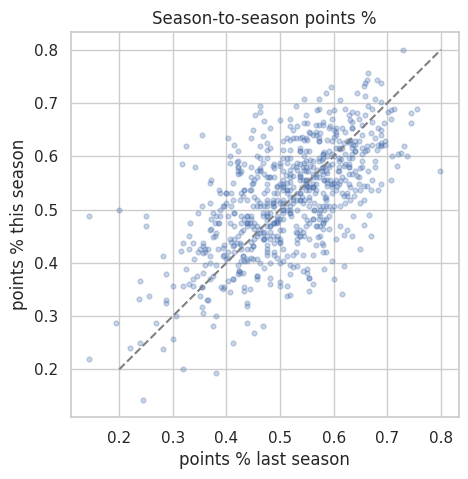

correlation: 0.615


In [11]:
era = nhl[(nhl["year"] >= 1980) & nhl["prev_pts_pct"].notna()].copy()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(era["prev_pts_pct"], era["pts_pct"], alpha=0.3, s=12)
ax.plot([0.2, 0.8], [0.2, 0.8], color="grey", linestyle="--")
ax.set(xlabel="points % last season", ylabel="points % this season", title="Season-to-season points %")
plt.show()

print("correlation:", round(era["pts_pct"].corr(era["prev_pts_pct"]), 3))

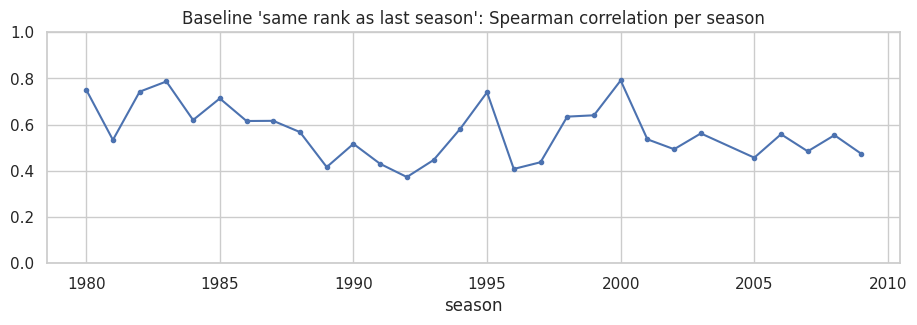

,spearman,mean_abs_rank_error,teams
year,,,
2001,0.54,6.13,30.0
2002,0.49,6.93,30.0
2003,0.56,6.67,30.0
2005,0.46,6.73,30.0
2006,0.56,6.03,30.0
2007,0.48,6.93,30.0
2008,0.55,6.30,30.0
2009,0.47,6.90,30.0


In [12]:
def rank_baseline(df):
    # Predict this season's league rank as last season's league rank (re-ranked among this season's teams).
    pred = df["prev_pts_pct"].rank(ascending=False, method="min")
    return pd.Series({
        "spearman": df["league_rank"].corr(pred, method="spearman"),
        "mean_abs_rank_error": (df["league_rank"] - pred).abs().mean(),
        "teams": len(df),
    })

baseline = era.groupby("year").apply(rank_baseline)

fig, ax = plt.subplots(figsize=(11, 3))
baseline["spearman"].plot(ax=ax, marker=".")
ax.set(title="Baseline 'same rank as last season': Spearman correlation per season", xlabel="season", ylim=(0, 1))
plt.show()

baseline.tail(8).round(2)

### Regression to the mean

Do strong teams tend to get weaker and weak teams stronger? This hints that a model should not just copy last season.

In [13]:
era["change"] = era["pts_pct"] - era["prev_pts_pct"]
era["last_season_group"] = pd.qcut(era["prev_pts_pct"], 5, labels=["Q1 (worst)", "Q2", "Q3", "Q4", "Q5 (best)"])
era.groupby("last_season_group", observed=True)["change"].agg(["mean", "std", "count"]).round(3)

,mean,std,count
last_season_group,,,
Q1 (worst),0.067,0.089,148
Q2,0.027,0.081,144
Q3,0.004,0.076,144
Q4,-0.027,0.081,145
Q5 (best),-0.052,0.072,142


## 6. Task (b): coach changes

`Coaches` has one row per coach per team-season. `stint` is the order of the coaches within that season, so `stint > 1` means a **mid-season** change.
A team can also change coach **between** seasons. We measure both.

In [14]:
nhl_coaches = coaches[coaches["lgID"] == "NHL"]
print(nhl_coaches["stint"].value_counts().sort_index())
print()
print(nhl_coaches["notes"].value_counts())

stint
1    1266
2     224
3      32
Name: count, dtype: Int64

notes
interim                      4
co-coach with Barry Smith    1
co-coach with Dave Lewis     1
Name: count, dtype: int64


In [15]:
# Coaches of the first stint and of the last stint of each team-season
season_coaches = nhl_coaches.groupby(["year", "tmID"]).apply(
    lambda g: pd.Series({
        "first_coaches": frozenset(g.loc[g["stint"] == g["stint"].min(), "coachID"]),
        "last_coaches": frozenset(g.loc[g["stint"] == g["stint"].max(), "coachID"]),
        "n_stints": g["stint"].nunique(),
    }),
    include_groups=False,
).reset_index()

tc = nhl.merge(season_coaches, on=["year", "tmID"], how="left")
tc = tc.sort_values(["franchID", "year"])
tc["prev_last_coaches"] = tc.groupby("franchID")["last_coaches"].shift(1)

has_prev = tc["prev_last_coaches"].notna() & tc["first_coaches"].notna()
tc["offseason_change"] = pd.NA
tc.loc[has_prev, "offseason_change"] = [
    a != b for a, b in zip(tc.loc[has_prev, "first_coaches"], tc.loc[has_prev, "prev_last_coaches"])
]
tc["midseason_change"] = tc["n_stints"] > 1
tc["any_change"] = tc["offseason_change"].fillna(False).astype(bool) | tc["midseason_change"]

print("Teams-seasons without coach data:", tc["first_coaches"].isna().sum())

Teams-seasons without coach data: 0


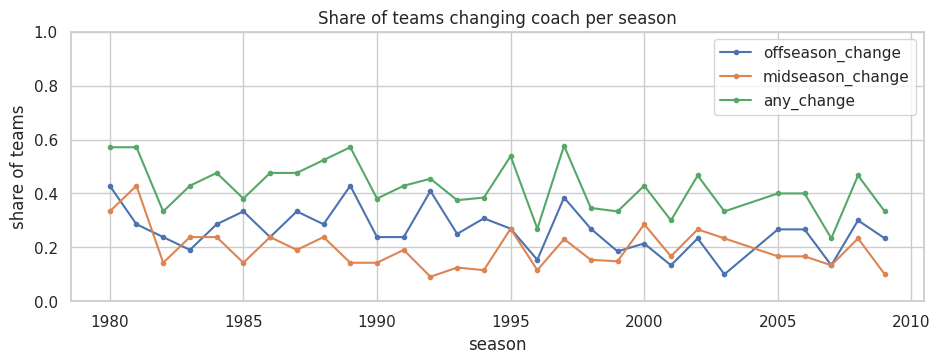

,overall share
offseason_change,0.257
midseason_change,0.194
any_change,0.416


In [16]:
modern_tc = tc[(tc["year"] >= 1980) & has_prev]
rates = modern_tc.groupby("year")[["offseason_change", "midseason_change", "any_change"]].mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
rates.plot(ax=ax, marker=".")
ax.set(title="Share of teams changing coach per season", xlabel="season", ylabel="share of teams", ylim=(0, 1))
plt.show()

modern_tc[["offseason_change", "midseason_change", "any_change"]].astype(float).mean().round(3).to_frame("overall share")

### Are coach changes linked to bad results the season before?

Everything here uses the **previous** season, so it is information we would have on prediction day.

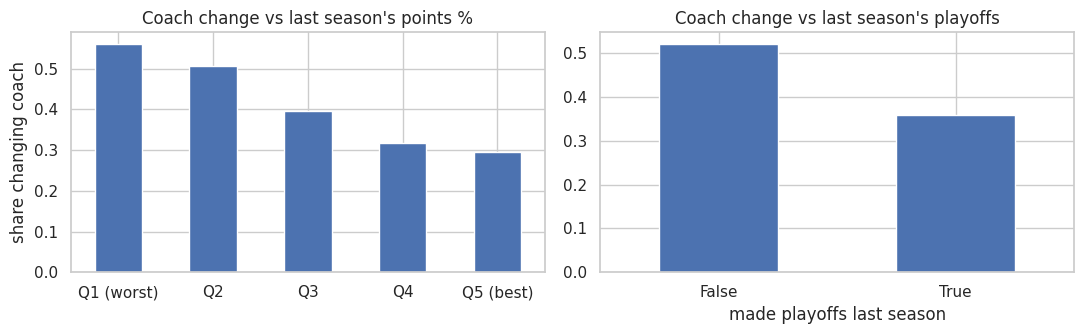

In [17]:
modern_tc = modern_tc.copy()
modern_tc["prev_made_playoffs"] = modern_tc["prev_playoff"].notna()
modern_tc["prev_pts_group"] = pd.qcut(modern_tc["prev_pts_pct"], 5, labels=["Q1 (worst)", "Q2", "Q3", "Q4", "Q5 (best)"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
modern_tc.groupby("prev_pts_group", observed=True)["any_change"].mean().plot.bar(ax=axes[0])
axes[0].set(title="Coach change vs last season's points %", xlabel="", ylabel="share changing coach")
modern_tc.groupby("prev_made_playoffs")["any_change"].mean().plot.bar(ax=axes[1])
axes[1].set(title="Coach change vs last season's playoffs", xlabel="made playoffs last season", ylabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Coach tenure: how many consecutive seasons the coach who finished last season had been finishing seasons with this franchise
def tenure_before(group):
    lasts = list(group["last_coaches"])
    out = [pd.NA]
    for i in range(1, len(lasts)):
        coach, n, j = lasts[i - 1], 0, i - 1
        while j >= 0 and lasts[j] == coach:
            n, j = n + 1, j - 1
        out.append(n)
    return pd.Series(out, index=group.index)

tc_valid = tc[tc["first_coaches"].notna()].copy()
tc_valid["prev_tenure"] = tc_valid.groupby("franchID", group_keys=False).apply(tenure_before, include_groups=False)
m = tc_valid[(tc_valid["year"] >= 1980) & tc_valid["prev_last_coaches"].notna()]
m.groupby(m["prev_tenure"].astype(int).clip(upper=5))["any_change"].agg(["mean", "count"]).rename(
    index={5: "5+"}, columns={"mean": "share changing coach", "count": "team-seasons"}
).round(3)

,share changing coach,team-seasons
prev_tenure,,
1,0.399,306
2,0.436,181
3,0.490,102
4,0.431,51
5+,0.337,83


## 7. Summary of findings

**Data scope**
- 1909–2009, 5 leagues. Only the NHL is relevant; 1980+ (after the WHA merger) is a sensible modelling era.
- **2004 is missing** (lockout) and **1994 had only 48 games** → use points % (`Pts / 2G`), not raw points.
- Some stats only exist in recent eras (OTL, shootouts, ...), so features must cope with missing columns in older seasons.
- `tmID` changes on relocation (7 franchises since 1979) → follow teams with **`franchID`**.

**Task (a) – ranking**
- `rank` in Teams is the **division** rank (max 7), not a league rank. We must decide which ranking we predict.
- Last season's points % correlates **≈ 0.62** with this season's.
- Baseline "same league rank as last season": Spearman ≈ **0.46–0.56** and ≈ **6–7 places** mean error (2001–2009). Our models must beat this.
- Strong **regression to the mean**: the worst 20% of teams gain ≈ +0.07 points % next season, the best 20% lose ≈ −0.05.

**Task (b) – coach changes**
- Since 1980, ≈ **26%** of teams change coach between seasons, ≈ **19%** during the season, ≈ **42%** either way. The classes are imbalanced, but not extremely.
- Changes are much more common after a bad season: ≈ 56% for the worst 20% of teams vs ≈ 30% for the best 20%; 52% after missing the playoffs vs 36% after making them.
- Coach tenure alone shows no clear pattern; it will need to be combined with results.
- **Open question:** on prediction day (day before the season), off-season changes have already happened. Does "change coaches" mean a **mid-season** change in the new season, or any change? To clarify with the lecturer.